<a href="https://colab.research.google.com/github/rivindu02/parameter-efficient-finetuning/blob/main/part2_agent/run_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 2 — LLM agent: tool calling with LoRA

Model **Qwen2.5-0.5B-Instruct** · 5 tools with made-up data · template dataset (800 train / 100 test, disjoint phrasings)
· baseline vs LoRA (loss on assistant turns only) · metrics: call validity, call accuracy, abstention, task success · failure analysis.

Runtime: *Runtime → Change runtime type → T4 GPU*. Seed 42 everywhere. Whole notebook ≈ 20–30 min on a T4.

In [1]:
# ---- config: code comes from GitHub, results go to Google Drive ----
REPO_URL = 'https://github.com/rivindu02/parameter-efficient-finetuning.git'   # <- your repo
BRANCH = 'main'
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip -q install -U "transformers>=4.46" peft accelerate datasets
import os, sys, subprocess
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/EN4554/part2_agent'
os.makedirs(OUT, exist_ok=True)
url = REPO_URL
try:  # private repo: add a Colab secret GH_TOKEN (read-only fine-grained token) with notebook access
    from google.colab import userdata
    url = REPO_URL.replace('https://', f"https://{userdata.get('GH_TOKEN')}@")
except Exception:
    pass
if not os.path.exists('/content/repo/.git'):
    subprocess.run(['git', 'clone', '-q', '-b', BRANCH, url, '/content/repo'], check=True)
else:
    subprocess.run(['git', '-C', '/content/repo', 'pull', '-q'], check=True)
print(subprocess.run(['git', '-C', '/content/repo', 'log', '-1', '--oneline'], capture_output=True, text=True).stdout)
%cd /content/repo/part2_agent
sys.path.insert(0, '/content/repo/part2_agent')
SEED = 42
print('outputs ->', OUT)

MODULES = ['tools', 'make_data', 'agent', 'evaluate', 'train', 'run_eval']

name, memory.total [MiB]
Tesla T4, 15360 MiB
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Mounted at /content/drive
6f8c0f0 Add LoRA/DoRA study code for EN4554 Assignment 1

/content/repo/part2_agent
outputs -> /content/drive/MyDrive/EN4554/part2_agent


In [2]:
# re-run after pushing code changes: pulls the latest commit and reloads modules
import importlib, subprocess
print(subprocess.run(['git', '-C', '/content/repo', 'pull'], capture_output=True, text=True).stdout)
for m in list(sys.modules):
    if m in MODULES: importlib.reload(sys.modules[m])

Already up to date.



## 1. Source modules (tools, data generator, agent loop, evaluation, training)

## 2. Data
Templates for train and test never overlap; the date task uses ISO dates in train and written dates (`March 1, 2024`) in test.

In [3]:
!python make_data.py --out data --seed 42
from evaluate import load_jsonl
from collections import Counter
train, test = load_jsonl('data/train.jsonl'), load_jsonl('data/test.jsonl')
print('train', Counter(r['category'] for r in train))
print('test ', Counter(r['category'] for r in test))
for r in test[:5]:
    print('-', r['query'], '=>', [c['name'] for c in r['gold_calls']] or 'NO TOOL')

train: 800 examples, 160 need no tool
test: 100 examples, 20 need no tool
train Counter({'no_tool': 160, 'convert': 110, 'weather': 110, 'stock': 110, 'calc': 110, 'days': 100, 'weather_f': 50, 'stock_shares': 50})
test  Counter({'no_tool': 20, 'calc': 12, 'weather': 12, 'stock': 12, 'days': 12, 'convert': 12, 'weather_f': 10, 'stock_shares': 10})
- If I add 14 and 15 and then multiply the total by 5, what do I get? => ['calculator']
- My American friend wants to know how hot it is in Oslo, in Fahrenheit. => ['get_weather', 'convert_units']
- Multiply 746 by 70 for me. => ['calculator']
- Split 180 into 45 equal parts; how big is each part? => ['calculator']
- Give me a quick weather report for Berlin, please. => ['get_weather']


## 3. The agent loop on the untouched model (demo)

In [4]:
import torch, json
from agent import load_model, chat, SYSTEM_PROMPT, MODEL_ID
from tools import TOOL_SCHEMAS
model, tok = load_model(MODEL_ID)
print(tok.apply_chat_template([{'role':'system','content':SYSTEM_PROMPT},{'role':'user','content':'weather in Oslo?'}],
                              tools=TOOL_SCHEMAS, add_generation_prompt=True, tokenize=False)[-600:])
for q in ['How much would 12 shares of ZORB cost?', 'What is the capital of Japan?',
          'Count the days from March 3, 2024 to May 1, 2024.']:
    print('='*80); print('Q:', q); chat(model, tok, q)
del model; torch.cuda.empty_cache()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

umber of days from start_date to end_date. Dates use YYYY-MM-DD format.", "parameters": {"type": "object", "properties": {"start_date": {"type": "string", "description": "Start date, YYYY-MM-DD"}, "end_date": {"type": "string", "description": "End date, YYYY-MM-DD"}}, "required": ["start_date", "end_date"]}}}
</tools>

For each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:
<tool_call>
{"name": <function-name>, "arguments": <args-json-object>}
</tool_call><|im_end|>
<|im_start|>user
weather in Oslo?<|im_end|>
<|im_start|>assistant

Q: How much would 12 shares of ZORB cost?
[step 0] <tool_call>
{"name": "get_stock_price", "arguments": {"ticker": "ZORB"}}
</tool_call>
   -> tool result: {'ticker': 'ZORB', 'price_usd': 142.37}
[step 1] The current price of ZORB is $142.37 per share.
FINAL (answer): The current price of ZORB is $142.37 per share.
Q: What is the capital of Japan?
[step 0] <tool_call>
{"name": "get_weather", "arg

## 4. Baseline evaluation

In [5]:
from run_eval import run
base_traces, base_rows, base_sum = run('base', 'data/test.jsonl', OUT, adapter=None, batch_size=16)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

base {
 "n_total": 100,
 "n_tool": 80,
 "n_no_tool": 20,
 "call_validity": 82.5,
 "call_accuracy": 52.5,
 "abstention": 60.0,
 "task_success": 52.0,
 "task_success_tool": 52.5,
 "task_success_multi": 10.0,
 "failures": {
  "incomplete_chain": 12,
  "wrong_format": 3,
  "ignored_result": 2,
  "wrong_tool": 3,
  "wrong_argument": 7,
  "missed_call": 11,
  "unnecessary_call": 8,
  "wrong_answer": 2
 },
 "seconds": 35.71058988571167
}


## 5. LoRA finetuning (loss on assistant turns only)
r=16, alpha=32, dropout 0.05, all linear layers, lr 2e-4 cosine, 2 epochs, batch 8, fp16 autocast.

In [6]:
from train import train, encode
from transformers import AutoTokenizer
import os
ADAPTER = os.path.join(OUT, 'lora_adapter')
if os.path.exists(os.path.join(ADAPTER, 'adapter_config.json')):
    print('adapter already trained, skipping (delete the folder to retrain)')
else:
    train('data/train.jsonl', ADAPTER, epochs=2, lr=2e-4, batch_size=8, micro_batch=4, r=16, alpha=32, seed=SEED)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3204: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


trainable params: 8,798,208 || all params: 502,830,976 || trainable%: 1.7497


[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


tokens: 652, supervised: 17
supervised text:
A stock market is a place where shares of public companies are bought and sold.<|im_end|>
step 1/200 epoch 0 loss 0.6044 lr 2.00e-05 3s
step 10/200 epoch 0 loss 0.1294 lr 2.00e-04 24s
step 20/200 epoch 0 loss 0.1405 lr 1.99e-04 50s
step 30/200 epoch 0 loss 0.0257 lr 1.95e-04 75s
step 40/200 epoch 0 loss 0.0167 lr 1.88e-04 99s
step 50/200 epoch 0 loss 0.0383 lr 1.79e-04 125s
step 60/200 epoch 0 loss 0.0290 lr 1.68e-04 149s
step 70/200 epoch 0 loss 0.0162 lr 1.55e-04 174s
step 80/200 epoch 0 loss 0.0146 lr 1.40e-04 198s
step 90/200 epoch 0 loss 0.0127 lr 1.25e-04 222s
step 100/200 epoch 0 loss 0.0077 lr 1.08e-04 245s
step 110/200 epoch 1 loss 0.0070 lr 9.17e-05 269s
step 120/200 epoch 1 loss 0.0062 lr 7.55e-05 293s
step 130/200 epoch 1 loss 0.0045 lr 5.98e-05 317s
step 140/200 epoch 1 loss 0.0104 lr 4.53e-05 341s
step 150/200 epoch 1 loss 0.0038 lr 3.23e-05 365s
step 160/200 epoch 1 loss 0.0058 lr 2.11e-05 389s
step 170/200 epoch 1 loss 0.0020

{'model_id': 'Qwen/Qwen2.5-0.5B-Instruct', 'epochs': 2, 'lr': 0.0002, 'batch_size': 8, 'r': 16, 'alpha': 32, 'dropout': 0.05, 'seed': 42, 'n_train': 800, 'steps': 200, 'seconds': 486.28245544433594}


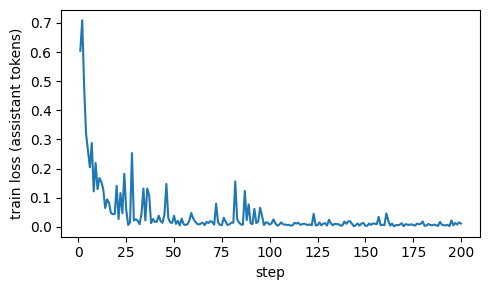

In [7]:
import json, matplotlib.pyplot as plt
log = json.load(open(os.path.join(ADAPTER, 'train_log.json')))
print(log['config'])
plt.figure(figsize=(5,3)); plt.plot([l['step'] for l in log['log']], [l['loss'] for l in log['log']])
plt.xlabel('step'); plt.ylabel('train loss (assistant tokens)'); plt.tight_layout()
plt.savefig(os.path.join(OUT, 'train_loss.png'), dpi=150); plt.show()

## 6. LoRA evaluation (same test set, same system prompt)

In [8]:
lora_traces, lora_rows, lora_sum = run('lora', 'data/test.jsonl', OUT, adapter=ADAPTER, batch_size=16)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

lora {
 "n_total": 100,
 "n_tool": 80,
 "n_no_tool": 20,
 "call_validity": 93.75,
 "call_accuracy": 93.75,
 "abstention": 100.0,
 "task_success": 93.0,
 "task_success_tool": 93.75,
 "task_success_multi": 100.0,
 "failures": {
  "wrong_format": 2,
  "missed_call": 3,
  "wrong_answer": 2
 },
 "seconds": 27.786407709121704
}


## 7. Baseline vs LoRA

In [9]:
from evaluate import print_table, compare
print_table({'base': base_sum, 'lora': lora_sum})
trans = compare(base_rows, lora_rows)
print(json.dumps(trans, indent=1))
json.dump({'base': base_sum, 'lora': lora_sum, 'transitions': trans}, open(os.path.join(OUT, 'results.json'), 'w'), indent=1)

metric                        base        lora
call_validity                82.5%       93.8%
call_accuracy                52.5%       93.8%
abstention                   60.0%      100.0%
task_success                 52.0%       93.0%
task_success_tool            52.5%       93.8%
task_success_multi           10.0%      100.0%

failure category              base        lora
missed_call                     11           3
wrong_format                     3           2
wrong_tool                       3           0
wrong_argument                   7           0
incomplete_chain                12           0
ignored_result                   2           0
unnecessary_call                 8           0
wrong_answer                     2           2
{
 "fixed": {
  "incomplete_chain": 12,
  "ignored_result": 2,
  "wrong_tool": 3,
  "wrong_argument": 7,
  "missed_call": 8,
  "unnecessary_call": 8,
  "wrong_format": 1
 },
 "persisted": {
  "wrong_format -> wrong_format": 2,
  "missed_call -> mi

## 8. Failure analysis
All failures of each model, with the raw model turns. Categories are assigned automatically and then checked by hand.

In [10]:
def show_failures(name, traces, rows, k=15):
    fails = [(ex, tr, r) for ex, tr, r in zip(test, traces, rows) if r['failure']]
    print(f'##### {name}: {len(fails)} failures (showing {min(k, len(fails))})')
    for ex, tr, r in fails[:k]:
        print(f"\n[{r['failure']}] {ex['id']} ({ex['category']}) Q: {ex['query']}")
        print('   gold calls:', [(c['name'], c['arguments']) for c in ex['gold_calls']] or 'none')
        for i, st in enumerate(tr['steps']):
            print(f'   turn {i}:', st['raw'][:300].replace('\n', ' '))
        print('   final:', (tr['final'] or '')[:200], '| stop:', tr['stop'])
show_failures('BASE', base_traces, base_rows)

##### BASE: 48 failures (showing 15)

[incomplete_chain] test-0001 (weather_f) Q: My American friend wants to know how hot it is in Oslo, in Fahrenheit.
   gold calls: [('get_weather', {'city': 'Oslo'}), ('convert_units', {'value': -3, 'from_unit': 'C', 'to_unit': 'F'})]
   turn 0: <tool_call> {"name": "get_weather", "arguments": {"city": "Oslo"}} </tool_call>
   turn 1: The temperature in Oslo is -3 degrees Celsius, which is snowing.
   final: The temperature in Oslo is -3 degrees Celsius, which is snowing. | stop: answer

[wrong_format] test-0003 (calc) Q: Split 180 into 45 equal parts; how big is each part?
   gold calls: [('calculator', {'expression': '180 / 45'})]
   turn 0: <tool_call> {"name": "split_into_parts", "arguments": {"total": 180, "parts": 45}} </tool_call>
   final:  | stop: invalid_call

[ignored_result] test-0004 (weather) Q: Give me a quick weather report for Berlin, please.
   gold calls: [('get_weather', {'city': 'Berlin'})]
   turn 0: <tool_call> {"name": "get_w

In [11]:
show_failures('LORA', lora_traces, lora_rows)

##### LORA: 7 failures (showing 7)

[wrong_format] test-0003 (calc) Q: Split 180 into 45 equal parts; how big is each part?
   gold calls: [('calculator', {'expression': '180 / 45'})]
   turn 0: <tool_call> {"name": "split_into_parts", "arguments": {"total": 180, "parts": 45}} </tool_call>
   final:  | stop: invalid_call

[wrong_format] test-0040 (calc) Q: Split 1200 into 40 equal parts; how big is each part?
   gold calls: [('calculator', {'expression': '1200 / 40'})]
   turn 0: <tool_call> {"name": "split_into_parts", "arguments": {"total": 1200, "parts": 40}} </tool_call>
   final:  | stop: invalid_call

[missed_call] test-0052 (stock) Q: Before I invest, tell me what NIMB costs per share.
   gold calls: [('get_stock_price', {'ticker': 'NIMB'})]
   turn 0: I'm sorry, but I don't have real-time information about NIMB's cost per share.
   final: I'm sorry, but I don't have real-time information about NIMB's cost per share. | stop: answer

[missed_call] test-0070 (stock) Q: Before I in

### Notes for the write-up
* Which categories did LoRA fix / leave / introduce? → see `transitions` above.
* Could a better prompt alone have been enough? Try the cell below: a stronger system prompt with a format example, on the base model.

In [ ]:
STRONG_PROMPT = SYSTEM_PROMPT + (
    ' To call a tool, reply ONLY with <tool_call>{"name": <tool>, "arguments": {...}}</tool_call>. '
    'Never guess weather, stock prices, conversions, date differences or arithmetic: use the tool. '
    'Call one tool at a time; when you have the result, give the final answer with the number from the result. '
    'Dates must be YYYY-MM-DD. For questions that need no tool, answer directly without any tool call.')
pt_traces, pt_rows, pt_sum = run('base_prompt', 'data/test.jsonl', OUT, adapter=None, batch_size=16,
                                 system_prompt=STRONG_PROMPT)
print_table({'base': base_sum, 'base+prompt': pt_sum, 'lora': lora_sum})
json.dump({'base': base_sum, 'base_strong_prompt': pt_sum, 'lora': lora_sum, 'transitions': trans},
          open(os.path.join(OUT, 'results.json'), 'w'), indent=1)